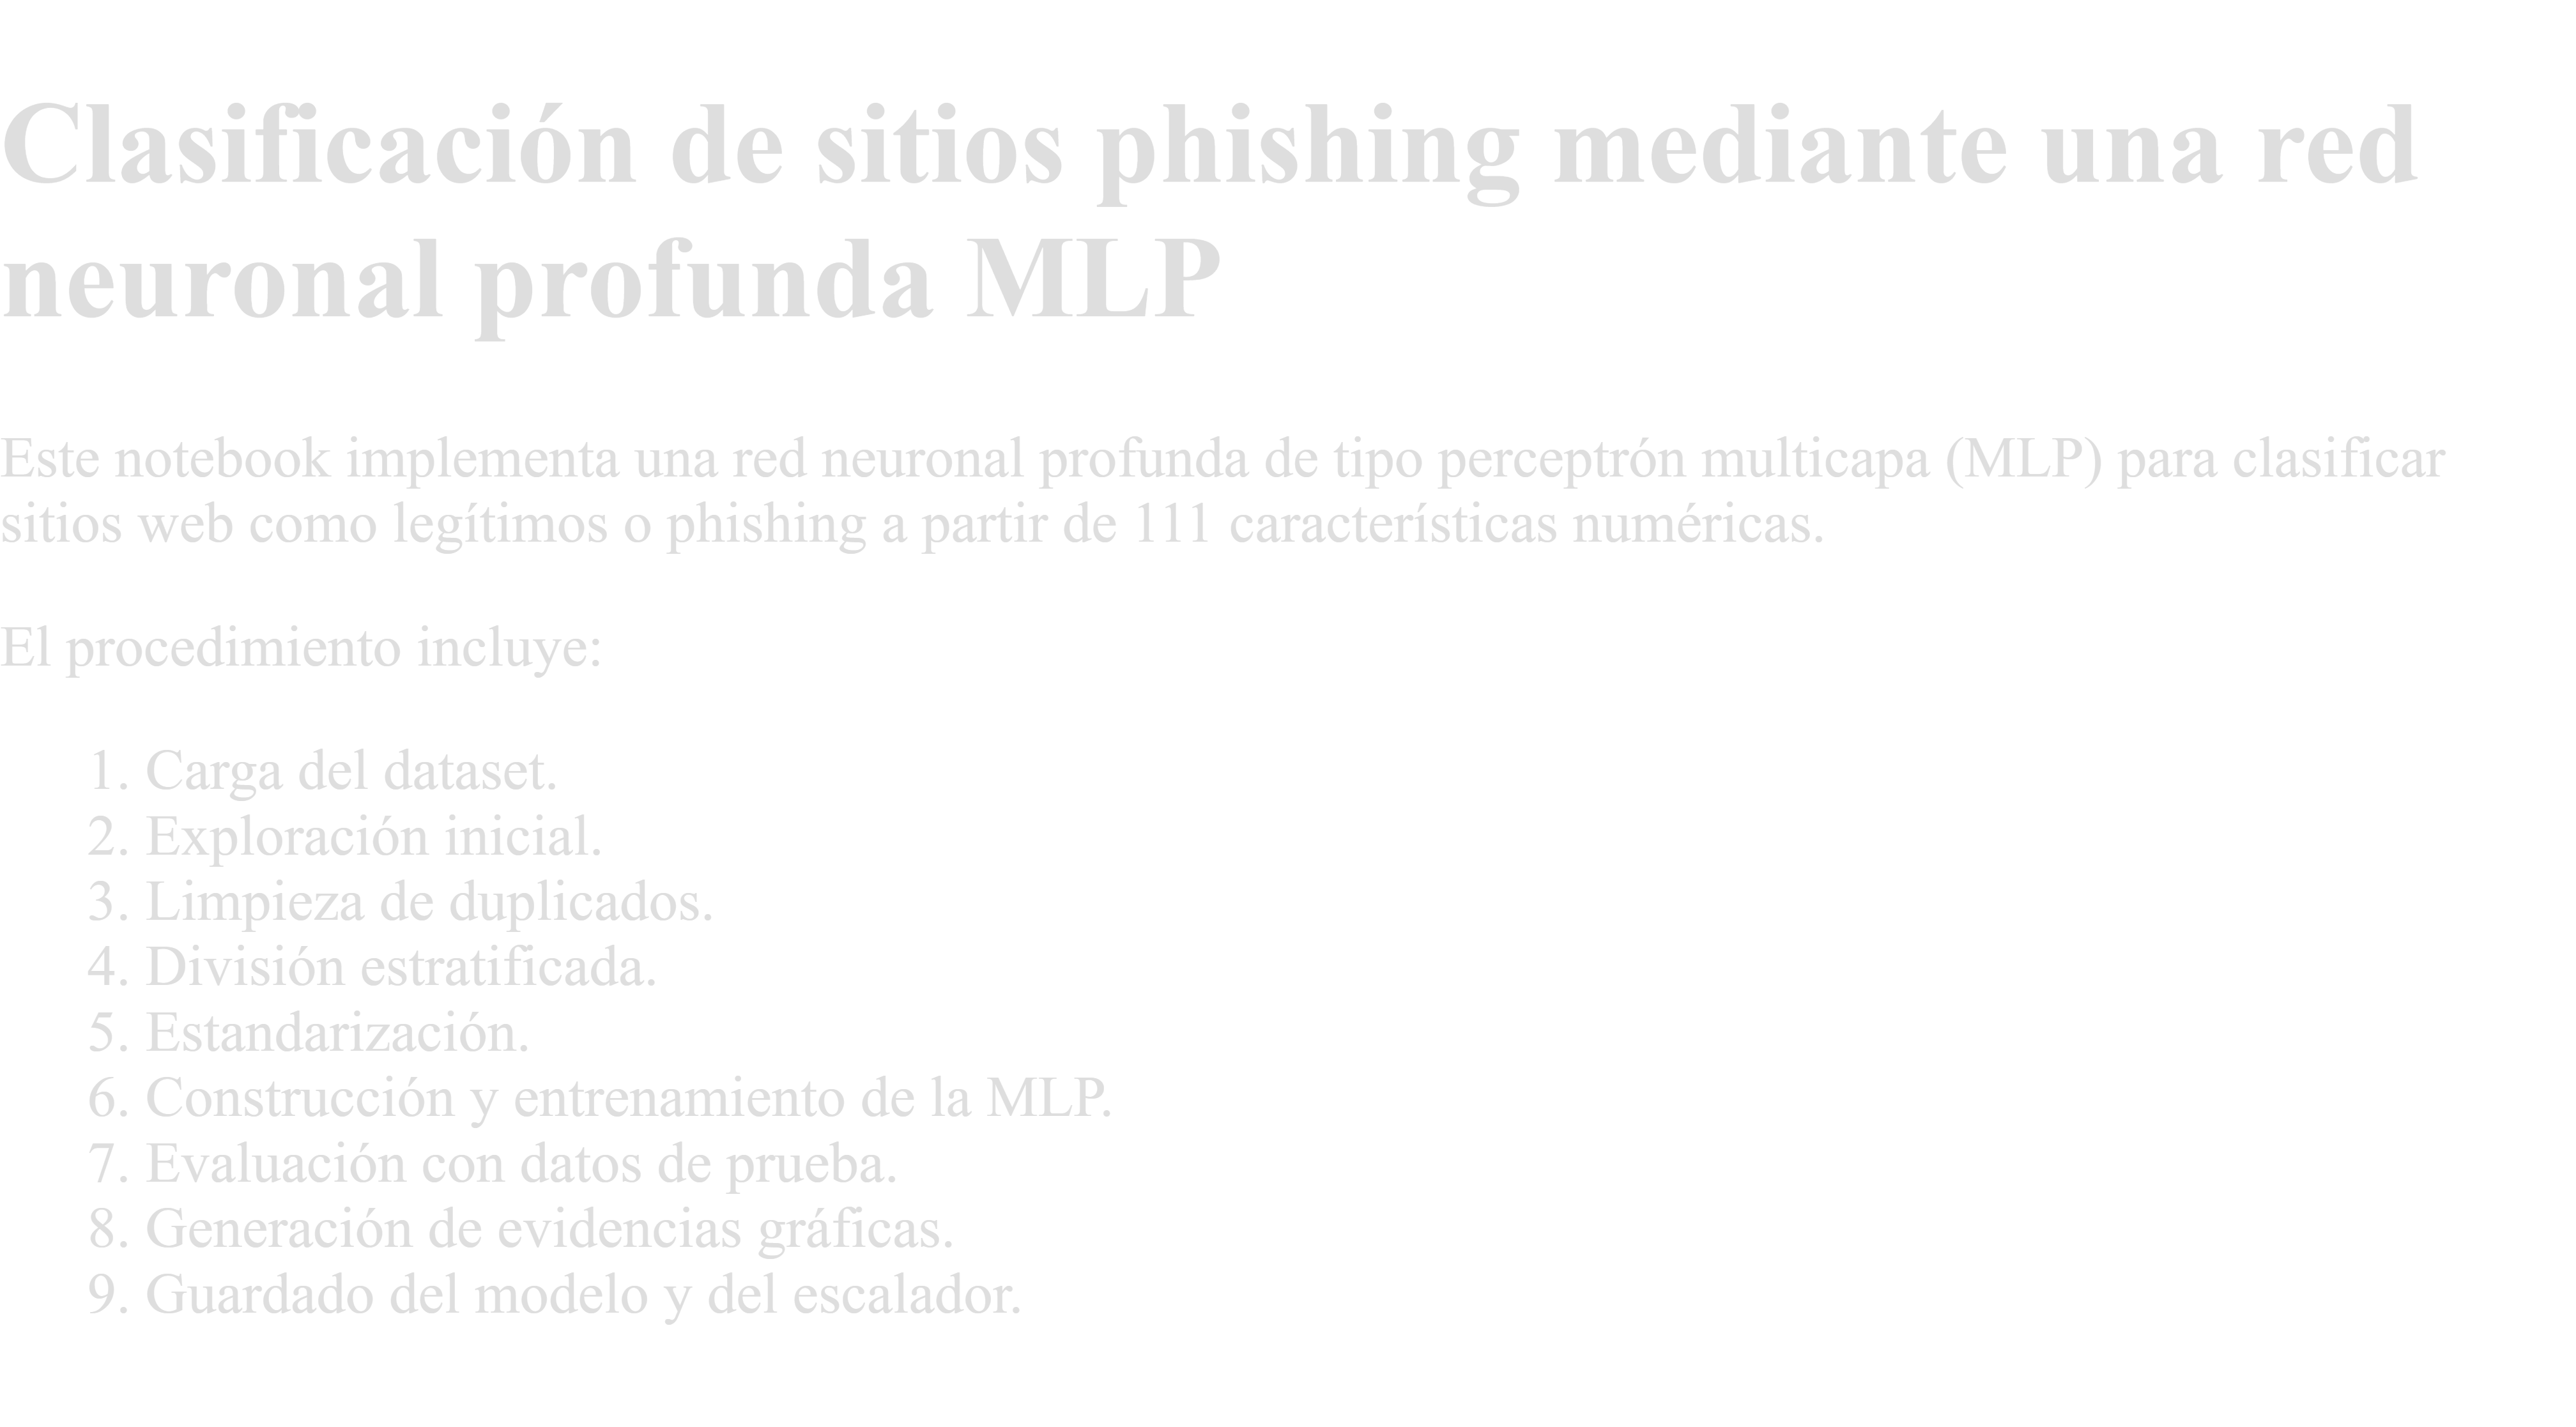

In [ ]:
import os
import random
import joblib
import urllib.request
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    roc_curve,
    roc_auc_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)
from tensorflow.keras.metrics import Precision, Recall, AUC

# Semilla para reproducibilidad
SEMILLA = 42

random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("Semilla configurada:", SEMILLA)

In [ ]:
import pandas as pd

URL_DATASET = "https://raw.githubusercontent.com/FabianAlbarracin/phishing-mlp/refs/heads/main/dataset_full.csv"

df_original = pd.read_csv(URL_DATASET)

print("Dataset cargado correctamente.")
print("Dimensiones:", df_original.shape)

## 1. Configuración de rutas

Se monta Google Drive y se definen las rutas del dataset y de los archivos de salida.

In [ ]:
# URL pública directa del dataset en GitHub
URL_DATASET = (
    "https://raw.githubusercontent.com/FabianAlbarracin/"
    "phishing-mlp/refs/heads/main/dataset_full.csv"
)

# Rutas temporales dentro de Google Colab
RUTA_DATASET = "/content/dataset_full.csv"
RUTA_RESULTADOS = "/content/resultados"

# Rutas de los archivos generados
RUTA_MODELO = os.path.join(
    RUTA_RESULTADOS,
    "modelo_phishing_mlp.keras"
)

RUTA_SCALER = os.path.join(
    RUTA_RESULTADOS,
    "scaler_phishing.pkl"
)

# Crear la carpeta de resultados
os.makedirs(RUTA_RESULTADOS, exist_ok=True)

# Descargar el dataset si aún no existe
if not os.path.exists(RUTA_DATASET):
    print("Descargando dataset público desde GitHub...")

    urllib.request.urlretrieve(
        URL_DATASET,
        RUTA_DATASET
    )

# Verificar que la descarga fue correcta
if not os.path.exists(RUTA_DATASET):
    raise FileNotFoundError(
        "No fue posible descargar el dataset."
    )

print("Dataset:", RUTA_DATASET)
print("Resultados:", RUTA_RESULTADOS)
print("Modelo:", RUTA_MODELO)
print("Escalador:", RUTA_SCALER)

## 2. Carga y exploración inicial del dataset

Se revisan las dimensiones, tipos de datos, valores nulos, valores infinitos, duplicados y distribución de la variable objetivo.

In [ ]:
df_original = pd.read_csv(RUTA_DATASET)

print("Dimensiones originales:", df_original.shape)
print("Número de variables predictoras:", df_original.shape[1] - 1)
print("Variable objetivo:", df_original.columns[-1])

total_nulos = int(df_original.isnull().sum().sum())

columnas_numericas = df_original.select_dtypes(
    include=np.number
)

total_infinitos = int(
    np.isinf(columnas_numericas).sum().sum()
)

total_duplicados = int(
    df_original.duplicated().sum()
)

print("\nValores nulos:", total_nulos)
print("Valores infinitos:", total_infinitos)
print("Filas duplicadas:", total_duplicados)

print("\nTipos de datos:")
print(df_original.dtypes.value_counts())

print("\nDistribución original:")
print(df_original["phishing"].value_counts())

print("\nDistribución porcentual original:")
print(
    df_original["phishing"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [ ]:
conteo_original = (
    df_original["phishing"]
    .value_counts()
    .sort_index()
)

etiquetas = ["Legítimo", "Phishing"]

plt.figure(figsize=(7, 5))

barras = plt.bar(
    etiquetas,
    conteo_original.values,
    color=["#2b5c8f", "#d9534f"],
    width=0.55
)

plt.title("Distribución original de las clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for barra in barras:
    cantidad = int(barra.get_height())

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 700,
        f"{cantidad:,}",
        ha="center"
    )

plt.tight_layout()

ruta_distribucion_original = os.path.join(
    RUTA_RESULTADOS,
    "distribucion_clases_original.png"
)

plt.savefig(
    ruta_distribucion_original,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_distribucion_original)

## 3. Limpieza del dataset

Se eliminan valores inválidos y registros duplicados. La eliminación de duplicados reduce el riesgo de que una misma observación aparezca simultáneamente en entrenamiento y prueba.

In [ ]:
df = (
    df_original
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

duplicados_eliminados = len(df_original) - len(df)

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df.shape)
print("Registros eliminados:", duplicados_eliminados)

print("\nDistribución final:")
print(df["phishing"].value_counts())

print("\nDistribución porcentual final:")
print(
    df["phishing"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nClases encontradas:")
print(sorted(df["phishing"].unique()))

assert df.shape == (87209, 112)
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0
assert set(df["phishing"].unique()) == {0, 1}

print("\nValidaciones completadas correctamente.")

In [ ]:
conteo_limpio = (
    df["phishing"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

barras = plt.bar(
    etiquetas,
    conteo_limpio.values,
    color=["#2b5c8f", "#d9534f"],
    width=0.55
)

plt.title("Distribución de clases después de la limpieza")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for barra in barras:
    cantidad = int(barra.get_height())

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 700,
        f"{cantidad:,}",
        ha="center"
    )

plt.tight_layout()

ruta_distribucion_limpia = os.path.join(
    RUTA_RESULTADOS,
    "distribucion_clases_limpia.png"
)

plt.savefig(
    ruta_distribucion_limpia,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_distribucion_limpia)

## 4. División y estandarización

El dataset limpio se divide de forma estratificada en:

- 70 % para entrenamiento.
- 15 % para validación.
- 15 % para prueba.

El escalador se ajusta exclusivamente con el conjunto de entrenamiento para evitar fuga de información.

In [ ]:
X = df.drop(columns=["phishing"])
y = df["phishing"]

nombres_variables = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEMILLA,
    stratify=y_temp
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nDistribución de entrenamiento:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribución de validación:")
print(
    y_val.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribución de prueba:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Entrenamiento estandarizado:", X_train_scaled.shape)
print("Validación estandarizada:", X_val_scaled.shape)
print("Prueba estandarizada:", X_test_scaled.shape)

print(
    "\nMedia aproximada del entrenamiento:",
    round(float(X_train_scaled.mean()), 6)
)

print(
    "Desviación aproximada del entrenamiento:",
    round(float(X_train_scaled.std()), 6)
)

## 5. Construcción de la red neuronal MLP

La arquitectura contiene dos capas ocultas con activación ReLU, regularización mediante Dropout y una salida Sigmoid para clasificación binaria.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)

model = Sequential([
    Input(
        shape=(X_train_scaled.shape[1],),
        name="entrada_caracteristicas"
    ),

    Dense(
        128,
        activation="relu",
        name="capa_densa_128"
    ),

    Dropout(
        0.30,
        name="dropout_30"
    ),

    Dense(
        64,
        activation="relu",
        name="capa_densa_64"
    ),

    Dropout(
        0.20,
        name="dropout_20"
    ),

    Dense(
        1,
        activation="sigmoid",
        name="salida_phishing"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)

model.summary()

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

## 6. Entrenamiento

El modelo se entrena durante un máximo de 30 épocas, utilizando lotes de 256 observaciones y el subconjunto de validación para controlar el proceso.

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(
        X_val_scaled,
        y_val
    ),
    epochs=30,
    batch_size=256,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

mejor_epoca = (
    int(np.argmin(history.history["val_loss"])) + 1
)

print("\nMejor época según val_loss:", mejor_epoca)
print(
    "Mejor pérdida de validación:",
    round(min(history.history["val_loss"]), 6)
)

## 7. Evaluación sobre el conjunto de prueba

El conjunto de prueba se utiliza después del entrenamiento para obtener una evaluación final sobre observaciones no utilizadas durante el ajuste de la red.

In [ ]:
resultados_test = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1,
    return_dict=True
)

print("\nRESULTADOS FINALES EN PRUEBA")

for metrica, valor in resultados_test.items():
    print(f"{metrica}: {valor:.4f}")

In [ ]:
y_prob = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

UMBRAL = 0.5

y_pred = (
    y_prob >= UMBRAL
).astype(int)

f1_phishing = f1_score(
    y_test,
    y_pred,
    pos_label=1
)

matriz = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = matriz.ravel()

print(f"F1-score para phishing: {f1_phishing:.4f}")

print("\nMatriz de confusión:")
print(matriz)

print("\nVerdaderos negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdaderos positivos:", tp)

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Legítimo",
            "Phishing"
        ],
        digits=4
    )
)

## 8. Evidencias gráficas

Se generan las curvas de entrenamiento, la matriz de confusión y la curva ROC.

In [ ]:
epocas = range(
    1,
    len(history.history["loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    epocas,
    history.history["accuracy"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas,
    history.history["val_accuracy"],
    label="Validación"
)

axes[0].set_title(
    "Exactitud durante el entrenamiento"
)

axes[0].set_xlabel("Época")
axes[0].set_ylabel("Exactitud")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epocas,
    history.history["loss"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas,
    history.history["val_loss"],
    label="Validación"
)

axes[1].set_title(
    "Pérdida durante el entrenamiento"
)

axes[1].set_xlabel("Época")
axes[1].set_ylabel("Pérdida")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

ruta_curvas = os.path.join(
    RUTA_RESULTADOS,
    "curvas_entrenamiento.png"
)

plt.savefig(
    ruta_curvas,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_curvas)

In [ ]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Legítimo",
        "Phishing"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(
    "Matriz de confusión del modelo MLP"
)

ax.set_xlabel(
    "Clasificación predicha"
)

ax.set_ylabel(
    "Clasificación real"
)

plt.tight_layout()

ruta_matriz = os.path.join(
    RUTA_RESULTADOS,
    "matriz_confusion.png"
)

plt.savefig(
    ruta_matriz,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz guardada en:")
print(ruta_matriz)

In [ ]:
fpr, tpr, umbrales = roc_curve(
    y_test,
    y_prob
)

auc_roc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Modelo MLP (AUC = {auc_roc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

plt.title("Curva ROC del modelo MLP")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(
    RUTA_RESULTADOS,
    "curva_roc.png"
)

plt.savefig(
    ruta_roc,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Curva ROC guardada en:")
print(ruta_roc)

## 9. Guardado del modelo y del escalador

Se guardan la red neuronal entrenada y el escalador utilizado en la preparación de los datos. Ambos archivos son necesarios para reutilizar correctamente el prototipo.

In [ ]:
model.save(RUTA_MODELO)
joblib.dump(scaler, RUTA_SCALER)

ruta_variables = os.path.join(
    RUTA_RESULTADOS,
    "variables_modelo.txt"
)

with open(
    ruta_variables,
    "w",
    encoding="utf-8"
) as archivo:

    for variable in nombres_variables:
        archivo.write(variable + "\n")

print("Modelo guardado en:")
print(RUTA_MODELO)

print("\nEscalador guardado en:")
print(RUTA_SCALER)

print("\nLista de variables guardada en:")
print(ruta_variables)

In [ ]:
ruta_resumen = os.path.join(
    RUTA_RESULTADOS,
    "resultados_finales.txt"
)

with open(
    ruta_resumen,
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        "RESULTADOS DEL MODELO MLP PARA PHISHING\n"
    )

    archivo.write("=" * 50 + "\n")

    archivo.write(
        f"Registros originales: {len(df_original)}\n"
    )

    archivo.write(
        f"Duplicados eliminados: {duplicados_eliminados}\n"
    )

    archivo.write(
        f"Registros finales: {len(df)}\n"
    )

    archivo.write(
        f"Registros de entrenamiento: {len(X_train)}\n"
    )

    archivo.write(
        f"Registros de validación: {len(X_val)}\n"
    )

    archivo.write(
        f"Registros de prueba: {len(X_test)}\n\n"
    )

    archivo.write(
        f"Accuracy: {resultados_test['accuracy']:.4f}\n"
    )

    archivo.write(
        f"Precision: {resultados_test['precision']:.4f}\n"
    )

    archivo.write(
        f"Recall: {resultados_test['recall']:.4f}\n"
    )

    archivo.write(
        f"F1-score: {f1_phishing:.4f}\n"
    )

    archivo.write(
        f"ROC-AUC: {auc_roc:.4f}\n"
    )

    archivo.write(
        f"Loss: {resultados_test['loss']:.4f}\n\n"
    )

    archivo.write(
        f"Verdaderos negativos: {tn}\n"
    )

    archivo.write(
        f"Falsos positivos: {fp}\n"
    )

    archivo.write(
        f"Falsos negativos: {fn}\n"
    )

    archivo.write(
        f"Verdaderos positivos: {tp}\n"
    )

print("Resumen guardado en:")
print(ruta_resumen)

In [ ]:
archivos_esperados = [
    RUTA_MODELO,
    RUTA_SCALER,
    ruta_variables,
    ruta_resumen,
    ruta_distribucion_original,
    ruta_distribucion_limpia,
    ruta_curvas,
    ruta_matriz,
    ruta_roc
]

print("COMPROBACIÓN FINAL\n")

todo_correcto = True

for ruta in archivos_esperados:
    existe = os.path.exists(ruta)

    estado = "OK" if existe else "FALTA"

    print(f"[{estado}] {os.path.basename(ruta)}")

    if not existe:
        todo_correcto = False

if todo_correcto:
    print(
        "\nNotebook ejecutado correctamente. "
        "Todos los archivos fueron generados."
    )
else:
    print(
        "\nFaltan archivos. Revisa las celdas anteriores."
    )